# Visualizing and optimizing a nonconvex objective

Plots a two-well surface and applies BFGS using the original analytic gradient and starting point.

Saved outputs are from the original coursework run, before the small fixes in this copy. The notebooks have not been rerun.


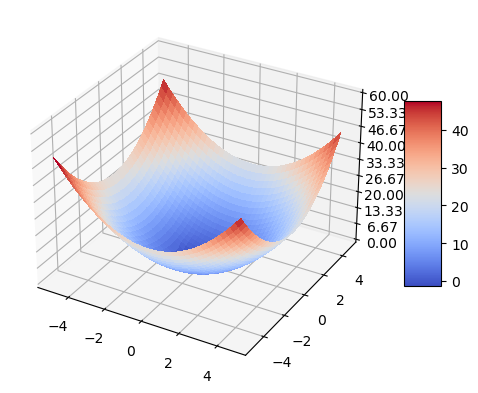

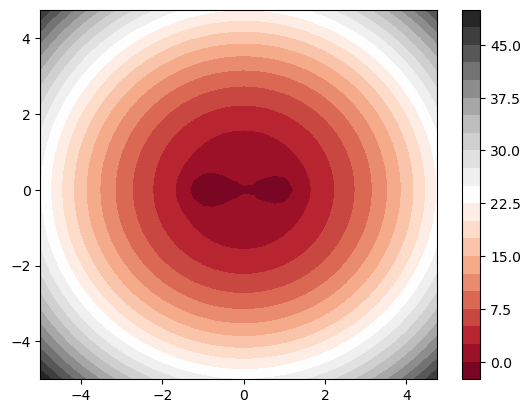

In [ ]:
from IPython.display import Math
from sympy import *
from sympy import symbols
from sympy.plotting import plot3d
from sympy.functions import exp
from sympy import symbols, hessian, exp
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
import numpy as np
from scipy.optimize import minimize

#f for plot
def f(x,y):
    return -2 * np.exp(-((x - 1) * (x - 1) + y * y) / .2) + -3 * np.exp(-((x + 1) * (x + 1) + y * y) / .2) + x * x + y * y
#f for solving
def g(x):
    return -2 * np.exp(-((x[0] - 1) * (x[0] - 1) + x[1] * x[1]) / .2) + -3 * np.exp(-((x[0] + 1) * (x[0] + 1) + x[1] * x[1]) / .2) + x[0] * x[0] + x[1] * x[1]
#grad of f
def grad_g(x):
    u=2*x[0] - 3*(-10.0*x[0] - 10.0)*np.exp(-5.0*x[1]**2 - 5.0*(x[0] + 1)**2) - 2*(-10.0*x[0] + 10.0)*np.exp(-5.0*x[1]**2 - 5.0*(x[0] - 1)**2)
    v=20.0*x[1]*np.exp(-5.0*x[1]**2 - 5.0*(x[0] - 1)**2) + 30.0*x[1]*np.exp(-5.0*x[1]**2 - 5.0*(x[0] + 1)**2) + 2*x[1]
    return u,v

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')


# Make data.
X = np.arange(-5, 5, 0.25)
Y = np.arange(-5, 5, 0.25)
X, Y = np.meshgrid(X, Y)

Z = f(X,Y)

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False)

# Customize the z axis.
ax.set_zlim(float(Z.min()), float(Z.max()))
ax.zaxis.set_major_locator(LinearLocator(10))
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

# Add a color bar which maps values to colors and plot
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()
plt.contourf(X, Y, Z, 20, cmap='RdGy')
plt.colorbar()



In [ ]:
#solving f
xguess= np.array([-4,4])
res = minimize(g, xguess, jac = grad_g, method='BFGS',
                options={'gtol': 1e-8, 'disp': True})
print (res)


Optimization terminated successfully.
         Current function value: -2.063090
         Iterations: 13
         Function evaluations: 26
         Gradient evaluations: 26
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -2.063090251768192
        x: [-9.363e-01 -1.365e-09]
      nit: 13
      jac: [ 3.386e-07 -4.286e-08]
 hess_inv: [[ 3.332e-02 -2.797e-05]
            [-2.797e-05  3.185e-02]]
     nfev: 26
     njev: 26